In [8]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import constants as const
from astropy import units as u
from sympy import *
from scipy.integrate import solve_ivp

For this assignment, I am letting you pick which packages to import and what font size / style to use for your plots. Make sure the axis ticks and labels are large enough to be readable.

#### Coriolis force

When a puck slides on a rotating turntable, it can come instantaneously to rest. From a perspective looking straight down on the turntable, plot the shape of the puck's path before it comes to rest. In a markdown cell, explain why this happens.

Text(0.5, 0.98, 'Path of puck coming to instantaneous rest')

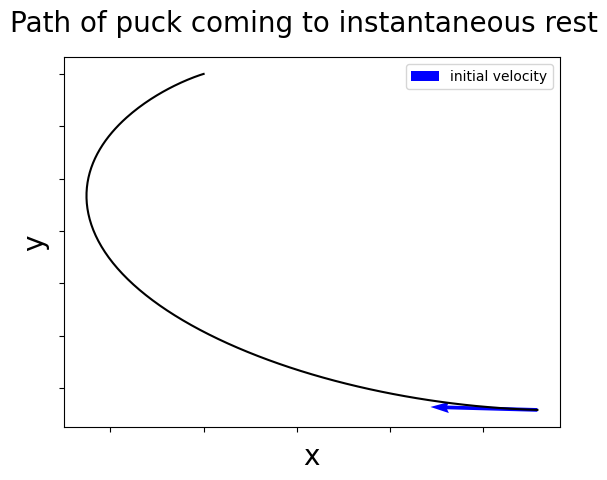

In [94]:
#what if I go reverse, make the final state (v = 0) the initial state

# Your code here

m = symbols('m:4') #the 'motion' array will have rx, ry, rdotx and rdoty
w = symbols('w') #omega, the magnitude of the angular velocity vector 
t = symbols('t') #time

rx = m[0]
ry = m[1]
vx = m[2]
vy = m[3]

w_val = [1] #arbitrary value for w
steps = 200 #number of steps 

m0 = [-1, 1, 0, 0] #'initial' conditions (set a point where the puck comes to rest)

mdot = [vx, vy, 2* vy * w + rx * w**2, -2*vx*w - ry * w**2]
mdot_reverse = [-vx, -vy, -2* vy * w + -rx * w**2, 2*vx*w + ry * w**2] #go back in time, dm/d(-t)
f = lambdify((t, m, w), mdot_reverse)

t_end = 2 #arbitrary stopping time 
t_eval = np.linspace(0, t_end, steps) 
solution0 = solve_ivp(f, (0, t_end), m0, t_eval=t_eval, args=w_val)

#make plot
'''fig, ax = plt.subplots(2)

ax[0].plot(solution0.t, solution0.y[2]) #x velocity vs time
ax[1].plot(solution0.t, solution0.y[3]) #y velocity vs time'''

fig, ax = plt.subplots(1)
ax.plot(solution0.y[0], solution0.y[1], color = 'k')
ax.quiver(solution0.y[0][-1], solution0.y[1][-1], solution0.y[2][-1], solution0.y[3][-1], 
           angles='xy', scale_units='xy', scale=5, color='b', label = 'initial velocity')

ax.set_xlabel('x', fontsize = 20)
ax.set_ylabel('y', fontsize = 20)
ax.legend()
ax.set_xticklabels([])
ax.set_yticklabels([])

fig.suptitle('Path of puck coming to instantaneous rest', fontsize = 20)

#aprint(solution0.y[0][0], solution0.y[1][0], solution0.y[2][0], solution0.y[3][0])

The puck's path in the rotating turntable frame deflects rightward. This is due to the Coriolis force, which is always perpendicular to the instantaneous velocity of the puck. It therefore changes the direction of the puck's velocity. In the inertial frame where the puck experiences no forces, it appears to move in a straight line. 

#### Surface deformation due to spinning

A bucket of water is spun about its vertical axis with angular speed $\Omega$. The water in the very center of the bucket has depth $h_0$. Assume the water has settled in equilibrium relative to the bucket. Plot the height of the water surface $h - h_0$ across a diameter of the bucket. To find $h(r)$, use cylindrical polar coordinates and remember that the surface is an equipotential under the combined effects of the gravitational and centrifugal forces.

$$F = - \nabla U$$
$$U_g = -mg(h - h_o)$$
$$U_{cf} = 0.5m\Omega^2 r^2$$
$$0 = U_{tot} = mg(h - h_o) + 0.5m\Omega^2 r^2$$
$$h - h_o = \frac{\Omega^2r^2}{2g}$$
$R_b =$ radius of the bucket
$$x = \frac{r}{R_b}$$
$$h - h_o = \frac{\Omega^2x^2R_b^2}{2g}$$

Text(0.5, 0.98, 'surface of the water')

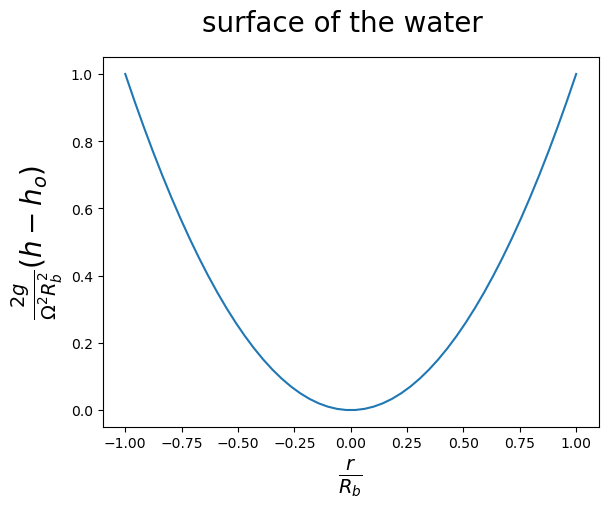

In [101]:
# Your code here

x = np.linspace(-1, 1, 50)

h = x**2

fig, ax = plt.subplots()

ax.plot(x, h)
ax.set_xlabel(r'$\frac{r}{R_b}$', fontsize = 20)
ax.set_ylabel(r'$\frac{2g}{\Omega^2R_b^2}(h - h_o)$', fontsize = 20)
fig.suptitle('surface of the water', fontsize = 20)


#### Ball drop on rotating Earth

A ball is dropped from a very tall stepladder on the equator. Plot the ball's path $z(x)$ from a tower due north of the stepladder. Explain in a markdown cell why the object lands east of its point of release.

Text(0.5, 0.98, 'Path of ball')

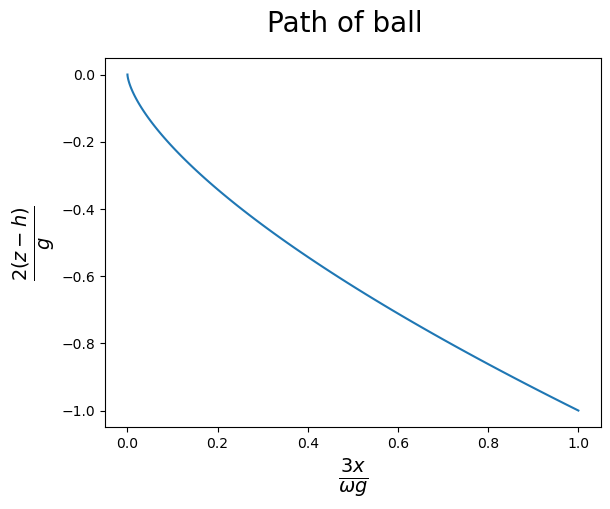

In [88]:
# Your code here

t = np.linspace(0, 1, 100)

#eom
x = t**3
z_h = -t**2

fig, ax = plt.subplots()
ax.plot(x, z_h)
ax.set_xlabel(r'$\frac{3x}{\omega g}$', fontsize = 20)
ax.set_ylabel(r'$\frac{2(z - h)}{g}$', fontsize = 20)
fig.suptitle('Path of ball', fontsize = 20)


The object lands east of its point of release because it experiences a Coriolis force in the non-inertial rotating frame of the Earth. 